# A02 · Parte 2 — EDA de la resistencia a la compresión del hormigón

**Autor:** Alejandro de la Peña

**Asignatura:** TPIA — Experto Universitario

## 1. Introducción y objetivos

El dataset recoge 1030 ensayos de hormigón. Para cada uno se conocen las cantidades de 7 componentes (en kg por m³):
cemento, escoria, ceniza volante, agua, superplastificante, árido grueso y árido fino, la **edad** de la muestra en días
y su **resistencia a la compresión** en MPa, que es la variable objetivo.

El objetivo es analizar los datos y ver qué componentes influyen más en la resistencia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

## 2. Carga y comprensión de los datos

Los nombres originales del Excel son largos; se renombran a nombres cortos siguiendo el orden de `Concrete_Readme.txt`.

In [2]:
df = pd.read_excel("datos/concrete/Concrete_Data.xls")
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
              "coarse_agg", "fine_agg", "age", "strength"]
df.head()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
df.shape

(1030, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


Hay **1030 filas y 9 columnas**, todas **numéricas**. Las 8 primeras son variables de entrada y `strength` es la variable
objetivo. Como la resistencia es un número continuo, se trata de un problema de **regresión**.

### 2.1 Inspección estadística inicial (medias, varianzas, rangos)

In [5]:
estadisticas = df.describe().T
estadisticas["varianza"] = df.var()
estadisticas["rango"] = df.max() - df.min()
estadisticas.round(2)

,count,mean,std,min,25%,50%,75%,max,varianza,rango
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0,10921.74,438.00
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4,7444.08,359.40
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1,4095.55,200.10
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0,456.06,125.25
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2,35.68,32.20
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0,6045.66,344.00
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6,6428.10,398.60
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0,3990.44,364.00
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6,279.08,80.27


In [6]:
# Porcentaje de ceros en cada columna
((df == 0).mean() * 100).round(1)

cement               0.0
slag                45.2
fly_ash             55.0
water                0.0
superplasticizer    36.8
coarse_agg           0.0
fine_agg             0.0
age                  0.0
strength             0.0
dtype: float64

- La **resistencia** media es de unos **35,8 MPa**, con valores entre 2,3 y 82,6 MPa.
- El **cemento** está en todas las mezclas (entre 102 y 540 kg/m³).
- La **escoria**, la **ceniza volante** y el **superplastificante** tienen muchos ceros (45 %, 55 % y 37 %): son aditivos
  que no se usan en todas las mezclas.
- La **edad** va de 1 a 365 días, pero la mediana es 28: la media (45,7) sale más alta por unos pocos ensayos muy largos.
- Las variables tienen **escalas muy distintas** (el superplastificante llega a 32 y el árido grueso a 1145), algo a
  tener en cuenta si después se entrena un modelo.

## 3. Limpieza de datos

In [7]:
print("Valores nulos:")
print(df.isna().sum())
print()
print("Filas duplicadas:", df.duplicated().sum())

Valores nulos:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64

Filas duplicadas: 25


In [8]:
df = df.drop_duplicates()
df.shape

(1005, 9)

No hay **valores nulos**, pero sí **25 filas duplicadas** (exactamente iguales en todo, incluida la resistencia). Se
eliminan para que no cuenten dos veces, y quedan **1005 filas**.

## 4. Análisis univariable

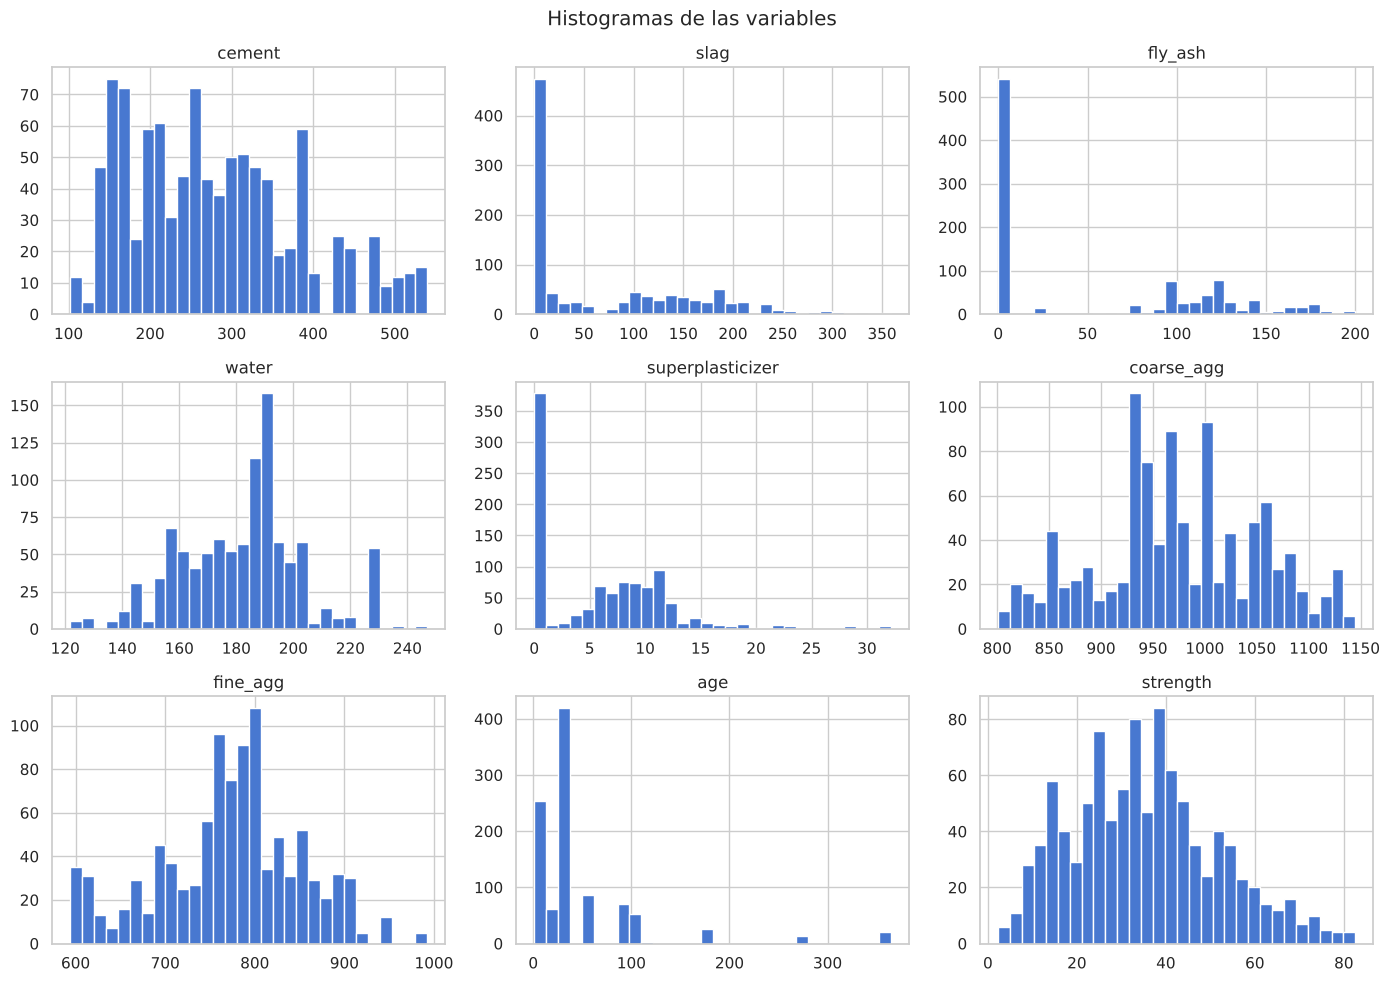

In [9]:
df.hist(bins=30, figsize=(14, 10))
plt.suptitle("Histogramas de las variables")
plt.tight_layout()
plt.show()

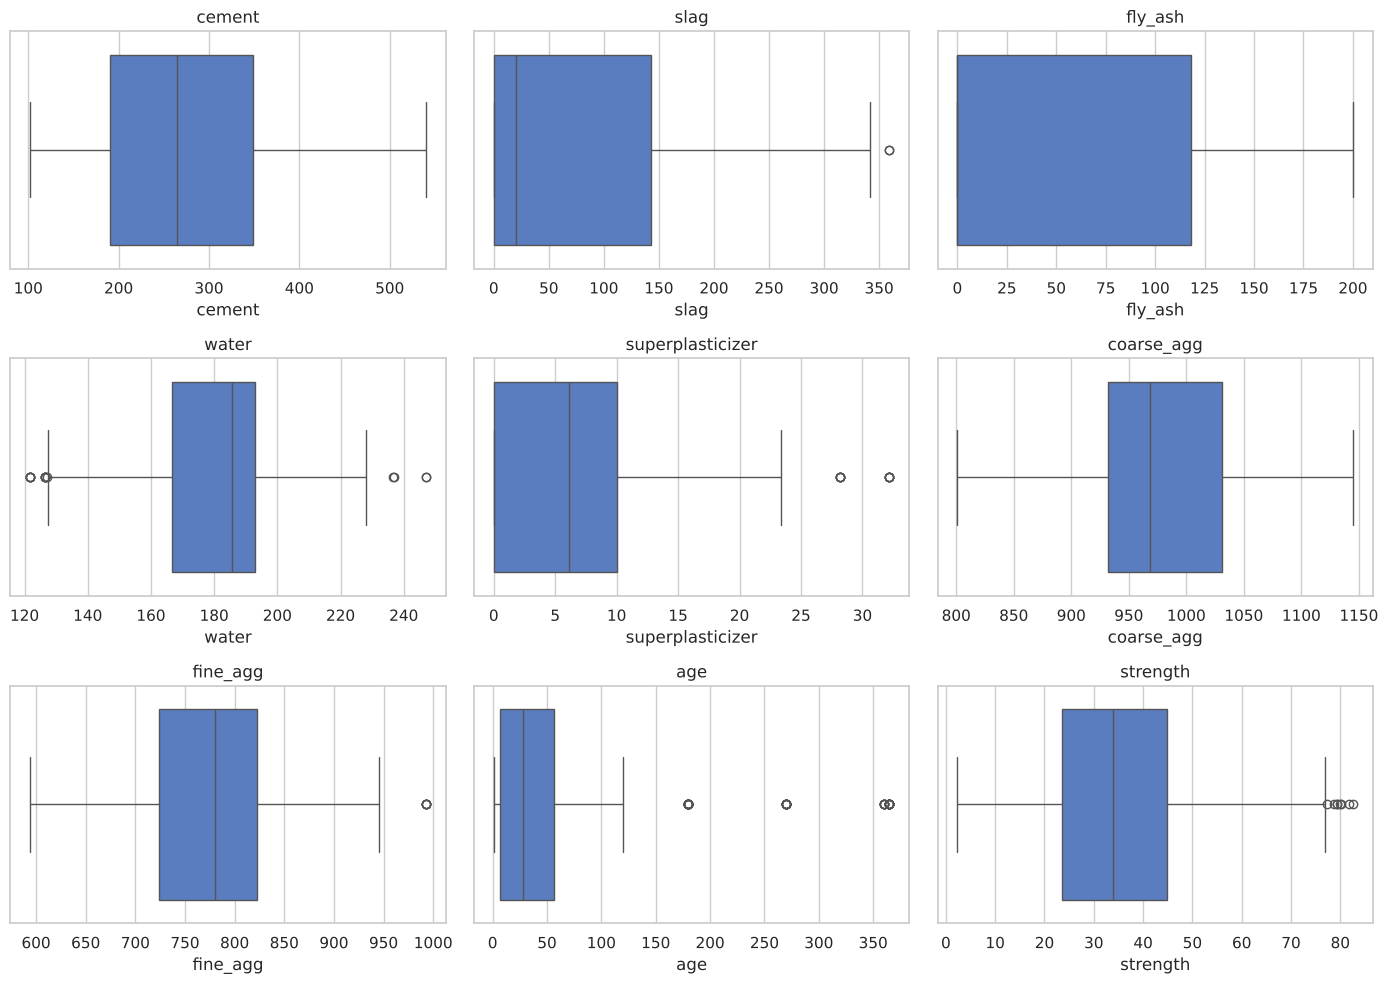

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
df['age'].value_counts().sort_index()

age
1        2
3      129
7      122
14      62
28     419
56      86
90      54
91      17
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64

- La **resistencia** tiene una distribución bastante simétrica, con la mayoría de valores entre 20 y 50 MPa.
- La **escoria**, la **ceniza volante** y el **superplastificante** tienen un pico muy grande en 0, por los muchos casos en
  que no se usan.
- El **agua** y los **áridos** tienen distribuciones más parecidas a una normal.
- La **edad** solo toma 14 valores distintos y la mayoría de ensayos se hicieron a **28 días**. En el boxplot, las edades
  de 180 a 365 días salen como atípicos, pero no son errores: son ensayos a largo plazo, así que se mantienen.
- Los pocos atípicos del resto de variables son valores posibles, por lo que tampoco se eliminan.

## 5. Análisis bivariable / multivariable

Correlaciones entre componentes y resistencia.

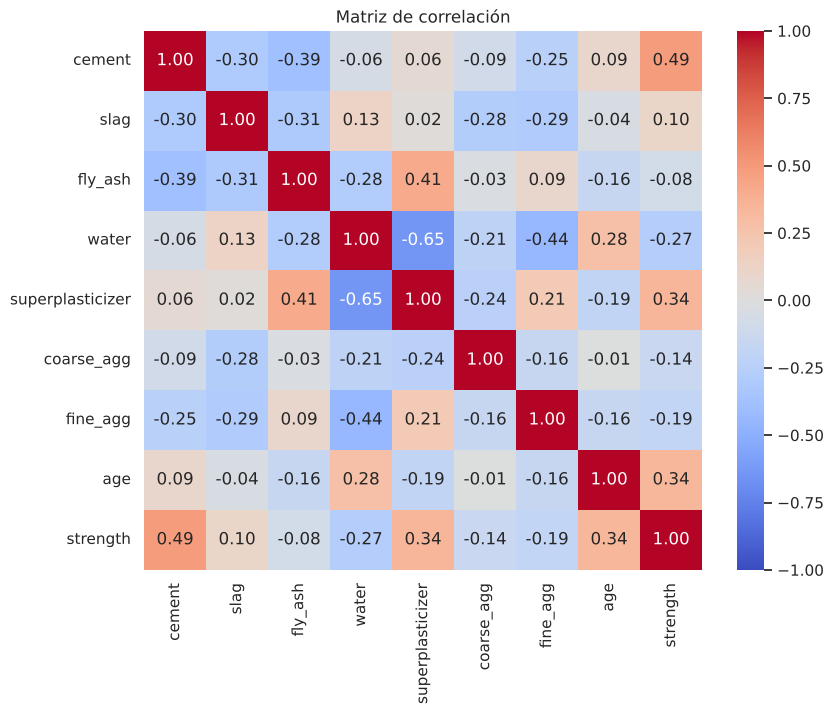

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

In [13]:
# Correlación de cada variable con la resistencia, ordenada
df.corr()["strength"].drop("strength").sort_values(ascending=False)

cement              0.488283
superplasticizer    0.344225
age                 0.337371
slag                0.103370
fly_ash            -0.080648
coarse_agg         -0.144710
fine_agg           -0.186457
water              -0.269606
Name: strength, dtype: float64

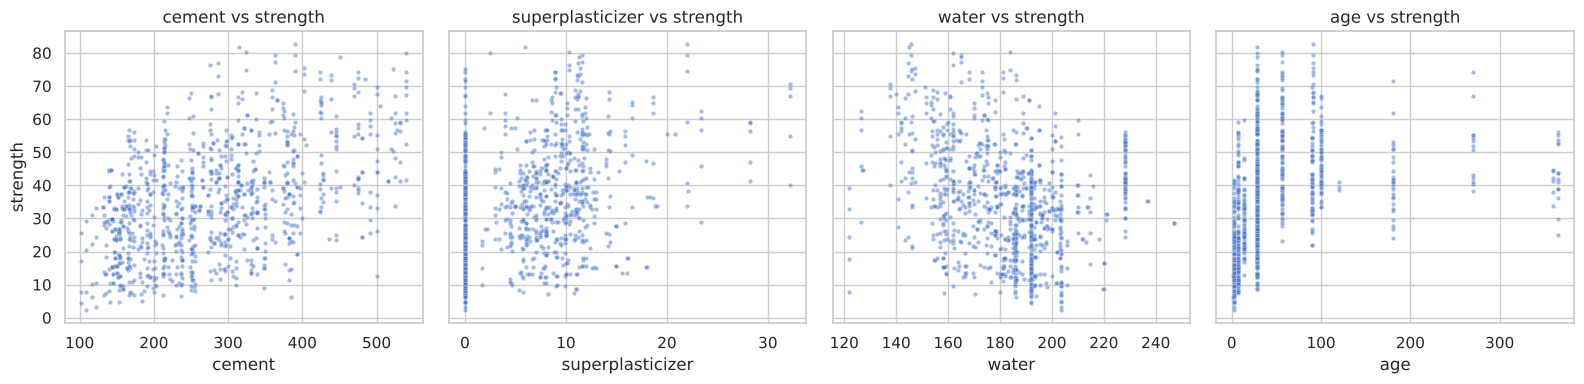

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["cement", "superplasticizer", "water", "age"]):
    sns.scatterplot(data=df, x=col, y="strength", ax=ax, s=10, alpha=0.5)
    ax.set_title(f"{col} vs strength")
plt.tight_layout()
plt.show()

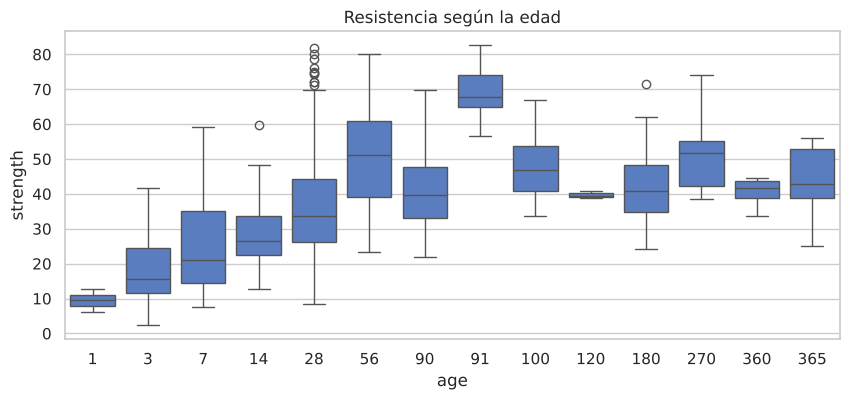

In [15]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="age", y="strength")
plt.title("Resistencia según la edad")
plt.show()

- El **cemento** es el componente con más relación con la resistencia (correlación **0,49**): más cemento, más
  resistencia.
- El **superplastificante** (**0,34**) y la **edad** (**0,34**) también tienen relación positiva.
- El **agua** tiene relación negativa (**−0,27**): cuanta más agua, menos resistente es el hormigón.
- La escoria, la ceniza y los áridos tienen correlaciones débiles con la resistencia.
- Entre componentes, la relación más fuerte es **agua – superplastificante (−0,65)**: las mezclas con superplastificante
  usan menos agua.
- En el gráfico por edad se ve que la resistencia **sube mucho los primeros días** (de unos 18 MPa a los 3 días a unos
  36 MPa a los 28 días) y luego crece más despacio. Por eso la relación con la edad no es lineal y la correlación (0,34) se
  queda corta para lo que realmente influye.

## 6. Conclusiones e insights

1. Los datos no tienen nulos; se han eliminado **25 filas duplicadas** y los atípicos se han mantenido porque son valores
   reales.
2. La resistencia media es de unos **36 MPa** y su distribución es bastante simétrica.
3. Los factores que más aumentan la resistencia son el **cemento**, el **superplastificante** y la **edad**; el **agua** la
   reduce.
4. La **edad** influye mucho, pero de forma no lineal: la resistencia crece rápido al principio y luego se estabiliza.
5. Varios componentes están relacionados entre sí (por ejemplo, agua y superplastificante), así que conviene analizarlos
   juntos y no solo uno a uno.